# CNNs

Part 1: FNN on MNIST. Great numbers, but it *sees* nothing (saliency = noise, scrambled pixels are fine).
Part 2: convolutions (slide, multiply, sum).

Now we bolt them together and let gradient descent learn the kernels:

1. Build + train a CNN on MNIST
2. Re-run the Part 1 experiments: saliency, scrambled pixels
3. Look inside: filters and feature maps
4. Deeper nets, the degradation problem, and the fix: ResNets
5. Load a real ResNet50, and ask *it* what it's looking at

## Three ideas

| Idea | What it means |
|---|---|
| Local receptive fields | each neuron only looks at a small patch; nearby pixels belong together |
| Weight sharing | one kernel, slid everywhere: the same detector reused across the whole image |
| Pooling | downsample: "is the pattern here, roughly?" Buys translation tolerance |

Our first CNN:

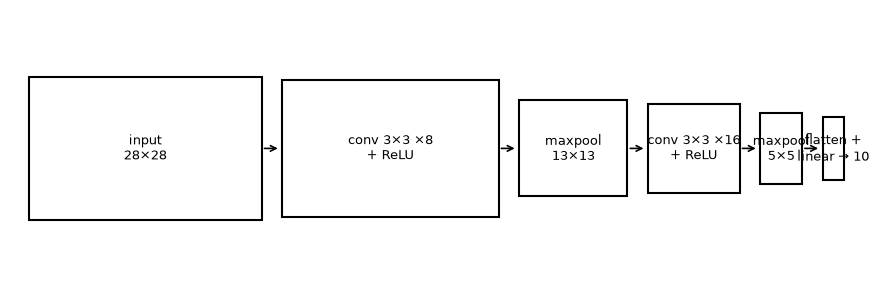

In [1]:
import matplotlib.pyplot as plt

# schematic of the pipeline: (label, spatial size, channels)
stages = [
    ("input\n28×28", 28, 1), ("conv 3×3 ×8\n+ ReLU", 26, 8), ("maxpool\n13×13", 13, 8),
    ("conv 3×3 ×16\n+ ReLU", 11, 16), ("maxpool\n5×5", 5, 16), ("flatten +\nlinear → 10", 2.5, 1),
]
fig, ax = plt.subplots(figsize=(11, 3.6))
x = 0.5
for i, (label, size, ch) in enumerate(stages):
    w = size * 0.22            # box width tracks spatial size
    h = 0.8 + size * 0.045     # so does height
    ax.add_patch(plt.Rectangle((x, 2 - h / 2), w, h, fill=False, lw=1.5))
    ax.text(x + w / 2, 2, label, ha="center", va="center", fontsize=9)
    x += w
    if i < len(stages) - 1:
        ax.annotate("", xy=(x + 0.5, 2), xytext=(x, 2), arrowprops=dict(arrowstyle="->", lw=1.2))
        x += 0.55
ax.set_xlim(0, x + 0.5); ax.set_ylim(0, 4); ax.axis("off")
plt.show()


## Warm-up: a conv layer in torch

`nn.Conv2d` is just a stack of kernels. Here's one with hand-set sobel weights, so we know what to expect:

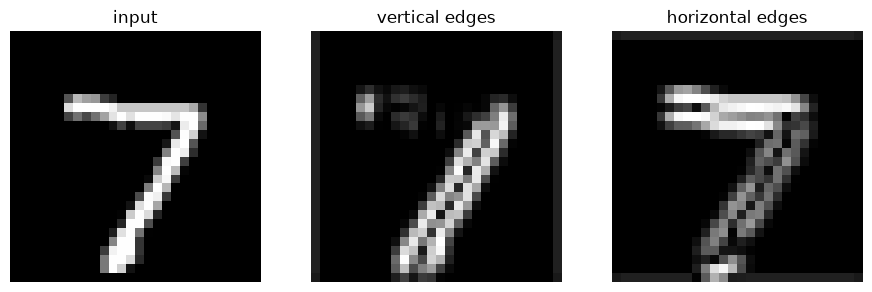

In [2]:
import torch
import torch.nn as nn
import torch.nn.functional as F
import torchvision
import torchvision.transforms as transforms
import numpy as np

torch.manual_seed(42)
np.random.seed(42)
device = torch.device("cuda" if torch.cuda.is_available()
                      else "mps" if torch.backends.mps.is_available() else "cpu")

transform = transforms.Compose([transforms.ToTensor(), transforms.Normalize((0.1307,), (0.3081,))])
train_set = torchvision.datasets.MNIST("data", train=True, download=True, transform=transform)
test_set = torchvision.datasets.MNIST("data", train=False, download=True, transform=transform)
train_loader = torch.utils.data.DataLoader(train_set, batch_size=128, shuffle=True)
test_loader = torch.utils.data.DataLoader(test_set, batch_size=1024)

digit = test_set[0][0].unsqueeze(0)                  # a nice '7'; add batch dim
sobel = nn.Conv2d(1, 2, 3, padding=1, bias=False)    # 2 kernels: one per edge direction
with torch.no_grad():
    sobel.weight[0, 0] = torch.tensor([[1., 0., -1.], [2., 0., -2.], [1., 0., -1.]])   # vertical, hand-set
    sobel.weight[1, 0] = torch.tensor([[1., 2., 1.], [0., 0., 0.], [-1., -2., -1.]])  # horizontal
    edges = sobel(digit)[0]  # (2, 28, 28): one channel per kernel

fig, axes = plt.subplots(1, 3, figsize=(11, 3.8))
for ax, im, title in zip(axes, [digit[0, 0], edges[0].abs(), edges[1].abs()],
                         ["input", "vertical edges", "horizontal edges"]):
    ax.imshow(im, cmap="gray"); ax.set_title(title); ax.axis("off")
plt.show()


## Train a real one

Two conv layers and one linear layer. Watch the parameter count: fewer knobs than the FNN, better results.

In [3]:
class CNN(nn.Module):
    def __init__(self):
        super().__init__()
        self.features = nn.Sequential(
            nn.Conv2d(1, 8, 3), nn.ReLU(), nn.MaxPool2d(2),     # 28 -> 26 -> 13
            nn.Conv2d(8, 16, 3), nn.ReLU(), nn.MaxPool2d(2),    # 13 -> 11 -> 5
        )
        self.head = nn.Sequential(nn.Flatten(), nn.Linear(16 * 5 * 5, 10))  # 5x5 map per channel -> 10 classes

    def forward(self, x):
        return self.head(self.features(x))

model = CNN().to(device)
print(f"CNN parameters: {sum(p.numel() for p in model.parameters()):,}")
print("FNN parameters: 235,146  <- the Part 1 network, and it wasn't even deep")


CNN parameters: 5,258
FNN parameters: 235,146  <- the Part 1 network, and it wasn't even deep


In [4]:
def evaluate(model, loader):
    model.eval()
    correct = 0
    with torch.no_grad():  # no gradients needed for testing
        for x, y in loader:
            x, y = x.to(device), y.to(device)
            correct += (model(x).argmax(1) == y).sum().item()
    return correct / len(loader.dataset)

opt = torch.optim.Adam(model.parameters(), lr=1e-3)
for epoch in range(1, 4):
    model.train()
    for x, y in train_loader:
        x, y = x.to(device), y.to(device)
        opt.zero_grad()  # clear old gradients
        loss = F.cross_entropy(model(x), y)
        loss.backward()
        opt.step()
    print(f"epoch {epoch} | test acc {evaluate(model, test_loader):.4f}")

print(f"\nFNN (Part 1): 97.92%  |  CNN: {evaluate(model, test_loader):.2%}  — with 45× fewer parameters")


epoch 1 | test acc 0.9663


epoch 2 | test acc 0.9783


epoch 3 | test acc 0.9822



FNN (Part 1): 97.92%  |  CNN: 98.22%  — with 45× fewer parameters


## Saliency, take two

Same trick as Part 1: gradient of the class score with respect to every pixel. Last time: TV static. This time?

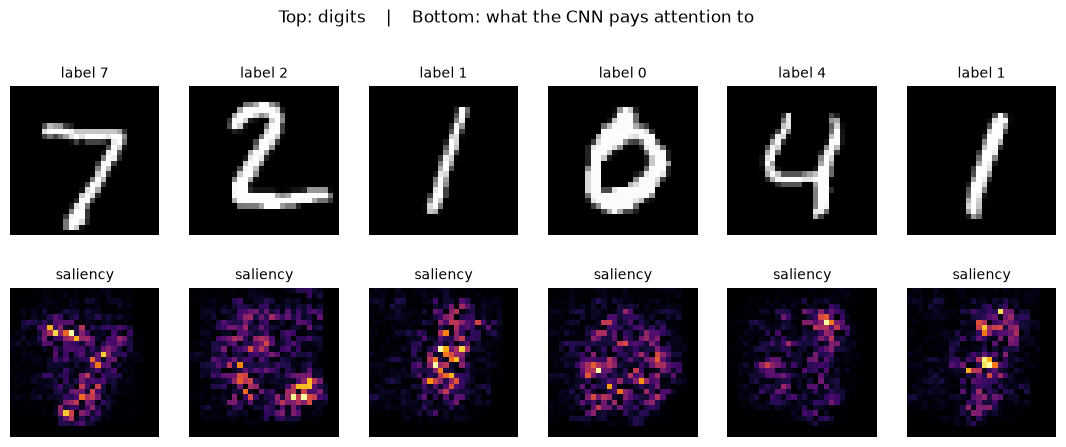

In [6]:
def saliency(model, x):
    x = x.to(device).clone().requires_grad_(True)  # ask for gradients on the input pixels
    logits = model(x)
    score = logits.gather(1, logits.argmax(1, keepdim=True)).sum()  # predicted-class scores only
    score.backward()
    return x.grad.abs().cpu(), logits.argmax(1).cpu()  # |grad| per pixel, plus predictions

x, y = next(iter(test_loader))
x = x[:6]
sal, pred = saliency(model, x)

fig, axes = plt.subplots(2, 6, figsize=(13.5, 4.8))
for i in range(6):
    axes[0, i].imshow(x[i].squeeze(), cmap="gray")
    axes[1, i].imshow(sal[i].squeeze(), cmap="inferno")  # bright = matters to the net
    axes[1, i].set_title("saliency", fontsize=10)
    for r in (0, 1): axes[r, i].axis("off")
fig.suptitle("Top: digits    |    Bottom: what the CNN pays attention to", y=1.02)
plt.show()


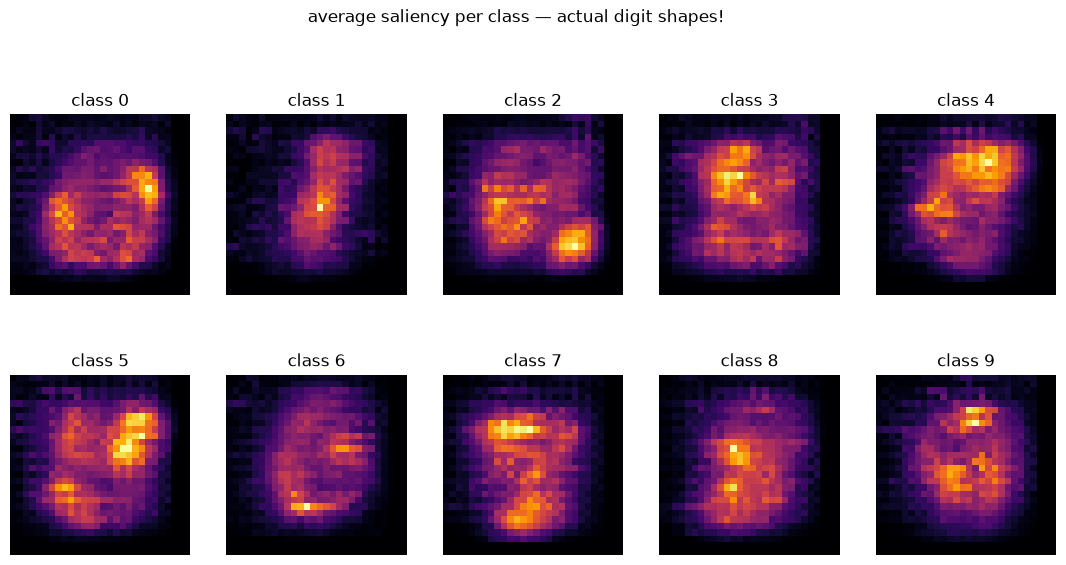

alignment between saliency and the digit's ink: 0.77   (the FNN managed ~0.3)


In [7]:
# average saliency + average 'ink' per class, then see how well they line up
model.eval()
sal_sum = torch.zeros(10, 28, 28); ink_sum = torch.zeros(10, 28, 28); cnt = torch.zeros(10)
for x, y in test_loader:
    x_dev = x.to(device).clone().requires_grad_(True)
    logits = model(x_dev)
    logits.gather(1, logits.argmax(1, keepdim=True)).sum().backward()
    g = x_dev.grad.abs().mean(1).cpu()
    ink = (x > 0).float()[:, 0]   # digits are bright strokes on a dark background
    for c in range(10):
        m = y == c                # images of class c in this batch
        sal_sum[c] += g[m].sum(0); ink_sum[c] += ink[m].sum(0); cnt[c] += m.sum()

sal_avg = sal_sum / cnt[:, None, None]  # mean saliency map per class
fig, axes = plt.subplots(2, 5, figsize=(13.5, 6.2))
for c in range(10):
    axes.flat[c].imshow(sal_avg[c], cmap="inferno"); axes.flat[c].axis("off")
fig.suptitle("average saliency per class — actual digit shapes!", y=1.02)
plt.show()

def corr(a, b):
    a, b = a.flatten() - a.mean(), b.flatten() - b.mean()  # pearson correlation by hand
    return (a @ b / (a.norm() * b.norm())).item()

align = np.mean([corr(sal_avg[c], ink_sum[c] / cnt[c]) for c in range(10)])
print(f"alignment between saliency and the digit's ink: {align:.2f}   (the FNN managed ~0.3)")


Strokes, not static. Each class's map is a ghostly version of the digit itself; the CNN genuinely learned a visual concept of each class. 8s get two loops, 7s get the crossbar.

## The scrambled test, take two

Scramble every pixel with one fixed permutation; the FNN didn't care at all (98.02%). The CNN should mind rather more:

In [8]:
perm = torch.randperm(784)  # one fixed pixel shuffle, reused for every image

def scramble(x):
    return x.flatten(1)[:, perm].view(-1, 1, 28, 28)

model.eval()
correct = 0
with torch.no_grad():
    # no retraining: just run the trained CNN on scrambled inputs
    for x, y in test_loader:
        correct += (model(scramble(x).to(device)).argmax(1).cpu() == y).sum().item()
scrambled_acc = correct / len(test_set)

print(f"FNN  on scrambled MNIST: 98.02%   (unbothered)")
print(f"CNN  on scrambled MNIST: {scrambled_acc:.2%}   (deeply bothered)")
print(f"CNN  on clean MNIST:     {evaluate(model, test_loader):.2%}")


FNN  on scrambled MNIST: 98.02%   (unbothered)
CNN  on scrambled MNIST: 11.31%   (deeply bothered)


CNN  on clean MNIST:     98.22%


## "Just go deeper": a problem

More layers should mean more capacity. Instead, plain deep nets get *worse*, and it isn't overfitting (training error goes up too). Optimising through dozens of stacked nonlinearities just gets muddled:

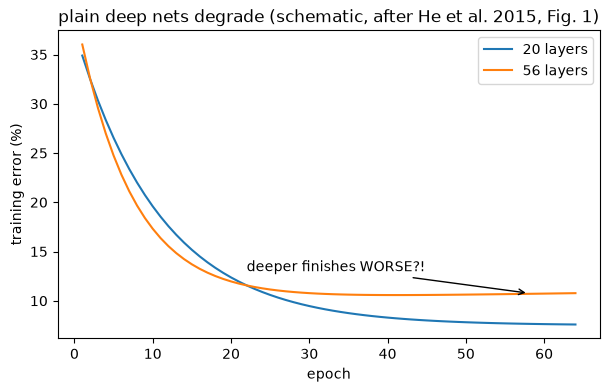

In [9]:
# numbers mimic He et al.'s reported training errors
ep = np.arange(1, 65)
deep = 10 + 30 * np.exp(-ep / 7) + ep * 0.012    # deeper net settles at a WORSE error
shallow = 7.5 + 30 * np.exp(-ep / 11)

plt.figure(figsize=(7, 4))
plt.plot(ep, shallow, label="20 layers")
plt.plot(ep, deep, label="56 layers")
plt.annotate("deeper finishes WORSE?!", xy=(58, deep[-1]), xytext=(22, 13),
             arrowprops=dict(arrowstyle="->"), fontsize=10)
plt.xlabel("epoch"); plt.ylabel("training error (%)")
plt.title("plain deep nets degrade (schematic, after He et al.)")
plt.legend(); plt.show()


## The fix: skip connections (ResNets, 2015)

Give the gradient a shortcut around each block:

$$y = F(x, \{W_i\}) + x$$

* If a layer isn't useful, the block can learn $F \approx 0$ → it becomes an identity, so layers can be *skipped*
* The derivative of $+x$ is 1 → gradients flow straight through, even through 100+ layers

ResNet-50 uses a bottleneck per block (squeeze channels 1×1, convolve 3×3, expand 1×1), which keeps it cheap:

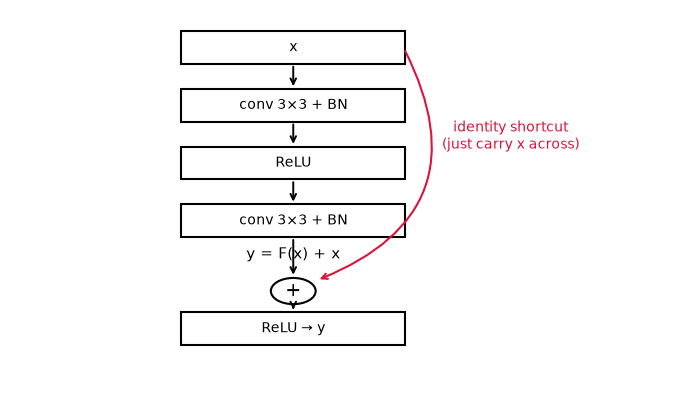

In [10]:
# draw one residual block: boxes, arrows, and the skip path
fig, ax = plt.subplots(figsize=(8.5, 5))
ax.set_xlim(0, 10); ax.set_ylim(0, 10); ax.axis("off")

def box(x, y, w, h, text):
    ax.add_patch(plt.Rectangle((x, y), w, h, fill=False, lw=1.5))
    ax.text(x + w / 2, y + h / 2, text, ha="center", va="center", fontsize=10)

def arrow(x1, y1, x2, y2):
    ax.annotate("", xy=(x2, y2), xytext=(x1, y1), arrowprops=dict(arrowstyle="->", lw=1.4))

cx, w, h = 2.6, 3.4, 0.85
box(cx, 8.6, w, h, "x")
box(cx, 7.1, w, h, "conv 3×3 + BN")
box(cx, 5.6, w, h, "ReLU")
box(cx, 4.1, w, h, "conv 3×3 + BN")
ax.add_patch(plt.Circle((cx + w / 2, 2.7), 0.34, fill=False, lw=1.5))
ax.text(cx + w / 2, 2.7, "+", ha="center", va="center", fontsize=14)  # the residual addition
box(cx, 1.3, w, h, "ReLU → y")
for y1, y2 in [(8.6, 7.95), (7.1, 6.45), (5.6, 4.95), (4.1, 3.05), (2.36, 2.15)]:
    arrow(cx + w / 2, y1, cx + w / 2, y2)
# identity shortcut: carry x around the whole stack, straight to the addition
ax.annotate("", xy=(cx + w / 2 + 0.36, 2.98), xytext=(cx + w - 0.02, 9.0),
            arrowprops=dict(arrowstyle="->", lw=1.5, connectionstyle="arc3,rad=-0.55", color="crimson"))
ax.text(7.6, 6.4, "identity shortcut\n(just carry x across)", color="crimson", fontsize=10, ha="center")
ax.text(cx + w / 2, 3.55, "y = F(x) + x", ha="center", fontsize=11)
plt.show()


In [11]:
class Bottleneck(nn.Module):
    def __init__(self, cin, cmid, cout):
        super().__init__()
        self.block = nn.Sequential(
            nn.Conv2d(cin, cmid, 1), nn.BatchNorm2d(cmid), nn.ReLU(),        # squeeze
            nn.Conv2d(cmid, cmid, 3, padding=1), nn.BatchNorm2d(cmid), nn.ReLU(),
            nn.Conv2d(cmid, cout, 1), nn.BatchNorm2d(cout),                  # expand
        )
        self.skip = nn.Conv2d(cin, cout, 1) if cin != cout else nn.Identity()  # match channels when they differ

    def forward(self, x):
        return F.relu(self.block(x) + self.skip(x))  # the residual addition

b = Bottleneck(256, 64, 512)
print(f"one ResNet-50 block: {sum(p.numel() for p in b.parameters()):,} parameters")


one ResNet-50 block: 219,520 parameters


## The real thing: ResNet50

* Stem: 7×7 conv + maxpool, then 4 stages of bottlenecks: [3, 4, 6, 3] blocks
* ~26M parameters, all ImageNet-pretrained. Ten years on, still everywhere as a backbone.

In [12]:
from torchvision.models import resnet50, ResNet50_Weights

weights = ResNet50_Weights.IMAGENET1K_V2
resnet = resnet50(weights=weights).eval()
print(f"total parameters: {sum(p.numel() for p in resnet.parameters()):,}\n")

# forward hooks record each top-level module's output shape
shapes = {}
def make_hook(name):
    def hook(module, inp, out): shapes[name] = tuple(out.shape)  # fires after each forward
    return hook
for name, module in resnet.named_children():
    module.register_forward_hook(make_hook(name))
with torch.no_grad():
    resnet(torch.zeros(1, 3, 224, 224))  # one dummy pass fills the dict

print(f"{'layer':<10}{'output shape':<22}params")
for name, module in resnet.named_children():
    n = sum(p.numel() for p in module.parameters())
    print(f"{name:<10}{str(shapes.get(name, '')):<22}{n:,}")


total parameters: 25,557,032

layer     output shape          params
conv1     (1, 64, 112, 112)     9,408
bn1       (1, 64, 112, 112)     128
relu      (1, 64, 112, 112)     0
maxpool   (1, 64, 56, 56)       0
layer1    (1, 256, 56, 56)      215,808
layer2    (1, 512, 28, 28)      1,219,584
layer3    (1, 1024, 14, 14)     7,098,368
layer4    (1, 2048, 7, 7)       14,964,736
avgpool   (1, 2048, 1, 1)       0
fc        (1, 1000)             2,049,000


## Does it really see?

A photo, the standard ImageNet preprocessing, top-5 predictions:

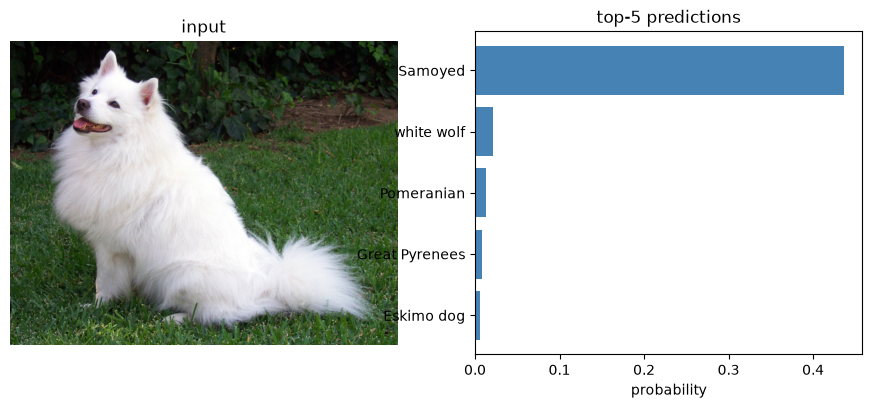

In [13]:
from PIL import Image

img = Image.open("images/dog.jpg").convert("RGB")
pre = weights.transforms()               # the preprocessing these weights were trained with
batch = pre(img).unsqueeze(0)            # add batch dim
with torch.no_grad():
    probs = resnet(batch).softmax(1)[0]  # logits -> probabilities
top = probs.topk(5)
labels = [weights.meta["categories"][i] for i in top.indices][::-1]  # reversed, so the top bar sits on top

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 4.2))
ax1.imshow(img); ax1.axis("off"); ax1.set_title("input")
ax2.barh(labels, top.values.numpy()[::-1], color="steelblue")
ax2.set_xlabel("probability"); ax2.set_title("top predictions")
plt.show()


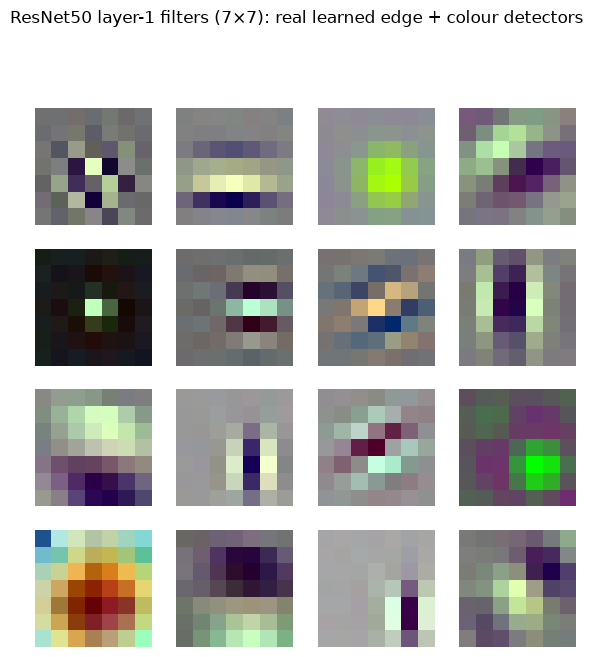

In [14]:
filters = resnet.conv1.weight.detach()[:16]  # the first 16 stem filters
fig, axes = plt.subplots(4, 4, figsize=(7, 7))
for i, ax in enumerate(axes.flat):
    f = filters[i].permute(1, 2, 0)          # channels-first -> channels-last for imshow
    f = (f - f.min()) / (f.max() - f.min())  # stretch to [0, 1] for display
    ax.imshow(f); ax.axis("off")
fig.suptitle("ResNet50 layer-1 filters: real learned edge + colour detectors", y=1.02)
plt.show()


## Grad-CAM: where is ResNet looking?

Take the last conv layer's activations (a 7×7 grid of 2048 channels), weight each channel by how much it pushed the predicted class (the gradient), sum, ReLU, overlay:

$$\text{CAM} = \operatorname{ReLU}\left(\sum_c \alpha_c A_c\right), \qquad \alpha_c = \frac{1}{HW}\sum_{h,w} \frac{\partial y_{\text{pred}}}{\partial A^c_{h,w}}$$

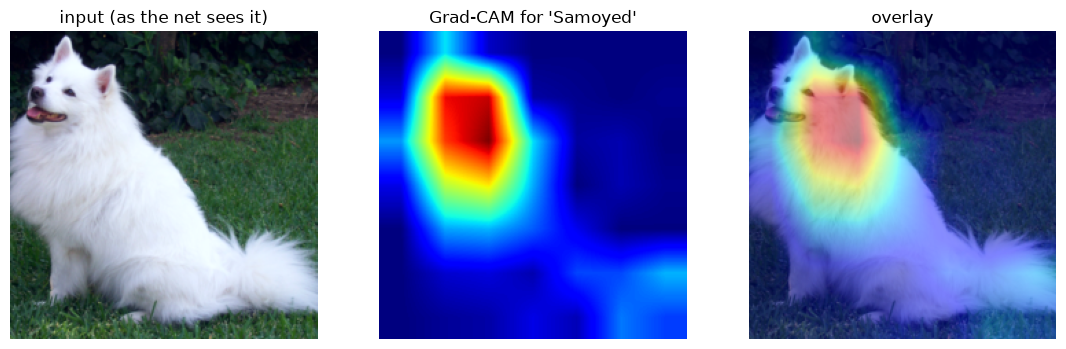

In [15]:
acts, grads = [], []
def fwd(module, inp, out): acts.append(out)    # grab final conv activations
def bwd(module, gi, go): grads.append(go[0])   # and their gradients
h1 = resnet.layer4[-1].register_forward_hook(fwd)
h2 = resnet.layer4[-1].register_full_backward_hook(bwd)

batch = pre(img).unsqueeze(0).requires_grad_(True)
pred_idx = resnet(batch).argmax(1).item()
resnet(batch)[0, pred_idx].backward()  # backprop the predicted class only
h1.remove(); h2.remove()

A, G = acts[0], grads[0]
alpha = G.mean(dim=(2, 3), keepdim=True)         # channel weight: mean gradient per channel
cam = F.relu((alpha * A).sum(1))[0]              # weighted sum of the activation maps
cam = (cam - cam.min()) / (cam.max() - cam.min())                # to [0, 1]
cam = F.interpolate(cam[None, None], size=224, mode="bilinear")[0, 0].detach()  # upsample to image size

unnorm = batch[0].detach() * 0.225 + 0.45  # (roughly) undo ImageNet normalisation
unnorm = unnorm.clamp(0, 1).permute(1, 2, 0)

fig, axes = plt.subplots(1, 3, figsize=(13.5, 4.6))
axes[0].imshow(unnorm); axes[0].set_title("input (as the net sees it)"); axes[0].axis("off")
axes[1].imshow(cam, cmap="jet"); axes[1].set_title(f"Grad-CAM for '{weights.meta['categories'][pred_idx]}'"); axes[1].axis("off")
axes[2].imshow(unnorm); axes[2].imshow(cam, cmap="jet", alpha=0.45); axes[2].set_title("overlay"); axes[2].axis("off")
plt.show()


## The family tree

| Net | Year | Big idea |
|---|---|---|
| AlexNet | 2012 | GPUs + dropout, kicked everything off |
| VGG | 2014 | just stacks of 3×3, depth by brute force |
| GoogLeNet | 2014 | Inception blocks: several kernel sizes in parallel |
| ResNet | 2015 | skip connections → 100+ layers, trains beautifully |
| MobileNet | 2017 | depthwise-separable convs, cheap enough for phones |
| EfficientNet | 2019 | scale width, depth *and* resolution together |
| ViT | 2020 | chop the image into patches, feed a transformer; attention eats vision too |